# Benchmarking técnico de modelos preentrenados

En esta actividad se utilizará Imagewoof como banco de pruebas. El dataset contiene diez categorías de ImageNet correspondientes a razas de perros visualmente similares.
Los modelos evaluados ya fueron entrenados previamente sobre ImageNet-1K. Por tanto, el experimento no modificará sus pesos

## Investigar y seleccionar los modelos

Según la documentación oficial de [TorchVision — Models and Pre-trained Weights](https://docs.pytorch.org/vision/stable/models.html) se eligen los siguientes modelos porque disponen de pesos preentrenados en ImageNet-1K y permiten realizar clasificación sobre sus 1.000 categorías  

Además representan enfoques arquitectónicos diveros: 

| Modelo | Arquitectura | Parámetros | GFLOPs | Top-1 ImageNet |
|---|---|---:|---:|---:|
| ResNet18 | CNN residual | 11.7 M | 1.81 | 69.76% |
| MobileNetV3-Large | CNN optimizada para eficiencia | 5.5 M | 0.22 | 75.27% |
| EfficientNet-B0 | CNN con escalamiento compuesto | 5.3 M | 0.39 | 77.69% |

Esta diversidad permite comparar no solo el desempeño de clasificación, sino también la relación entre precisión, tamaño del modelo y costo computacional bajo las mismas condiciones experimentales

## Preparar el entorno experimental

In [ ]:
import torch
import torchvision
import pandas as pd
import matplotlib.pyplot as plt
import platform
from pathlib import Path
from torchvision.datasets import ImageFolder
from PIL import Image
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import pandas as pd

from pathlib import Path
from PIL import Image

In [2]:
print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)

PyTorch: 2.14.0
TorchVision: 0.29.0


In [4]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)

Device: mps


In [7]:
print("Sistema:", platform.platform())
print("Procesador:", platform.processor())

Sistema: macOS-27.0.1-arm64-arm-64bit
Procesador: arm


## Preparar Imagewoof

In [9]:
data_dir = Path("data/imagewoof2")
val_dir = data_dir / "val"

print(val_dir.exists())

True


### Categorías disponibles

In [28]:
base_dataset = ImageFolder(val_dir)

print("Total de imágenes:", len(base_dataset))
print("Categorías:", len(base_dataset.classes))
print("Identificadores:", base_dataset.classes)

Total de imágenes: 3929
Categorías: 10
Identificadores: ['n02086240', 'n02087394', 'n02088364', 'n02089973', 'n02093754', 'n02096294', 'n02099601', 'n02105641', 'n02111889', 'n02115641']


### Imágenes disponibles por categoría

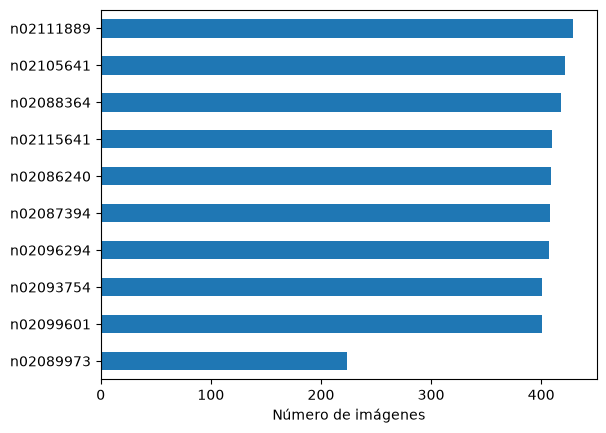

In [11]:
counts = {}

for folder in val_dir.iterdir():
    if folder.is_dir():
        counts[folder.name] = len(list(folder.glob("*")))

pd.Series(counts).sort_values().plot(kind="barh")
plt.xlabel("Número de imágenes")
plt.show()

## Carga de los modelos preentrenados

In [20]:
from torchvision.models import (
    resnet18,
    ResNet18_Weights,
    mobilenet_v3_large,
    MobileNet_V3_Large_Weights,
    efficientnet_b0,
    EfficientNet_B0_Weights
)

### Definición de la configuración de los modelos

In [21]:
models_config = {
    "ResNet18": {
        "builder": resnet18,
        "weights": ResNet18_Weights.IMAGENET1K_V1
    },
    "MobileNetV3-Large": {
        "builder": mobilenet_v3_large,
        "weights": MobileNet_V3_Large_Weights.IMAGENET1K_V2
    },
    "EfficientNet-B0": {
        "builder": efficientnet_b0,
        "weights": EfficientNet_B0_Weights.IMAGENET1K_V1
    }
}

### Carga de los modelos

In [ ]:
models = {}

for name, config in models_config.items():
    model = config["builder"](weights=config["weights"])
    model = model.to(device)
    model.eval()
    models[name] = model
    print(f"{name}: cargado")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/diana/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%


ResNet18: cargado
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /Users/diana/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100.0%


MobileNetV3-Large: cargado
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /Users/diana/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100.0%


EfficientNet-B0: cargado


In [23]:
from torch.hub import get_dir
print(get_dir())

/Users/diana/.cache/torch/hub


## Preparación del preprocesamiento

In [ ]:
preprocessors = {}

for name, config in models_config.items():
    preprocess = config["weights"].transforms()
    preprocessors[name] = preprocess
    print(f"\n{name}")
    print(preprocess)


ResNet18
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

MobileNetV3-Large
ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

EfficientNet-B0
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)


### Relacionar las etiquetas de Imagewoof con ImageNet 

In [26]:
imagewoof_to_imagenet = {
    "n02086240": 155,  # Shih-Tzu
    "n02087394": 159,  # Rhodesian ridgeback
    "n02088364": 162,  # Beagle
    "n02089973": 167,  # English foxhound
    "n02093754": 182,  # Border terrier
    "n02096294": 193,  # Australian terrier
    "n02099601": 207,  # Golden retriever
    "n02105641": 229,  # Old English sheepdog
    "n02111889": 258,  # Samoyed
    "n02115641": 273,  # Dingo
}

In [29]:
assert set(base_dataset.classes) == set(imagewoof_to_imagenet)

In [30]:
categories = models_config["ResNet18"]["weights"].meta["categories"]

for synset, idx in imagewoof_to_imagenet.items():
    print(synset, "→", idx, categories[idx])

n02086240 → 155 Shih-Tzu
n02087394 → 159 Rhodesian ridgeback
n02088364 → 162 beagle
n02089973 → 167 English foxhound
n02093754 → 182 Border terrier
n02096294 → 193 Australian terrier
n02099601 → 207 golden retriever
n02105641 → 229 Old English sheepdog
n02111889 → 258 Samoyed
n02115641 → 273 dingo


### Crear un dataset con preprocesamiento automático

In [36]:
class ImagewoofDataset(Dataset):

    def __init__(self, imagefolder, transform):
        self.samples = imagefolder.samples
        self.classes = imagefolder.classes
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, local_label = self.samples[index]
        image = Image.open(path).convert("RGB")
        image = self.transform(image)
        synset = self.classes[local_label]
        label = imagewoof_to_imagenet[synset]

        return image, label

### Creación de una instancia utilizando las transformaciones de ResNet18

In [ ]:
resnet_transform = models_config["ResNet18"]["weights"].transforms()
resnet_dataset = ImagewoofDataset(imagefolder = base_dataset, transform = resnet_transform)

print("Total de imágenes:", len(resnet_dataset))

Total de imágenes: 3929


### Comprobación de que la instancia puede cargar y transformar una imagen

In [ ]:
image_tensor, label = resnet_dataset[0]

print("Forma del tensor:", image_tensor.shape)
print("Tipo de dato:", image_tensor.dtype)
print("Etiqueta ImageNet:", label)

categories = models_config["ResNet18"]["weights"].meta["categories"]
print("Categoría:", categories[label])

Forma del tensor: torch.Size([3, 224, 224])
Tipo de dato: torch.float32
Etiqueta ImageNet: 155
Categoría: Shih-Tzu


### Crear los DataLoader para los tres modelos

In [ ]:
BATCH_SIZE = 16
loaders = {}

for name, config in models_config.items():
    transform = config["weights"].transforms()
    model_dataset = ImagewoofDataset(imagefolder=base_dataset, transform=transform)

    loaders[name] = DataLoader(
        model_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    print(name, ":", len(model_dataset), "imágenes")

ResNet18 : 3929 imágenes
MobileNetV3-Large : 3929 imágenes
EfficientNet-B0 : 3929 imágenes


In [41]:
for name, loader in loaders.items():
    images, labels = next(iter(loader))
    print(
        name,
        "| Imágenes:", tuple(images.shape),
        "| Etiquetas:", tuple(labels.shape)
    )

ResNet18 | Imágenes: (16, 3, 224, 224) | Etiquetas: (16,)
MobileNetV3-Large | Imágenes: (16, 3, 224, 224) | Etiquetas: (16,)
EfficientNet-B0 | Imágenes: (16, 3, 224, 224) | Etiquetas: (16,)


## Evaluación de la calidad predictiva

In [ ]:
def evaluate_accuracy(model, loader, device):
    model.eval()
    correct = 0
    total = 0

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return correct / total

In [ ]:
accuracy_results = {}

for name, model in models.items():
    accuracy = evaluate_accuracy(model, loaders[name], device)
    accuracy_results[name] = accuracy
    print(f"{name}: {accuracy:.2%}")

ResNet18: 77.40%
MobileNetV3-Large: 81.55%
EfficientNet-B0: 88.42%


## Perfilamiento estructural

In [46]:
def profile_model(model):

    total_params = sum(p.numel() for p in model.parameters())

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    params_bytes = sum(
        p.numel() * p.element_size()
        for p in model.parameters()
    )

    buffers_bytes = sum(
        b.numel() * b.element_size()
        for b in model.buffers()
    )

    return {
        "parameters": total_params,
        "trainable_parameters": trainable_params,
        "size_mib": (params_bytes + buffers_bytes) / 1024**2
    }

In [ ]:
profiles = {name: profile_model(model) for name, model in models.items()}
profiles_df = pd.DataFrame.from_dict(profiles, orient="index")

display(profiles_df)

,parameters,trainable_parameters,size_mib
ResNet18,11689512,11689512,44.628723
MobileNetV3-Large,5483032,5483032,21.009537
EfficientNet-B0,5288548,5288548,20.334862


## Preparación del benchmark y warm-up

In [57]:
def synchronize():
    torch.mps.synchronize()

In [58]:
WARMUP_RUNS = 10

for name, model in models.items():

    images, _ = next(iter(loaders[name]))
    images = images.to(device)

    model.eval()

    with torch.inference_mode():
        for _ in range(WARMUP_RUNS):
            _ = model(images)

    synchronize()

    print(name, "→ warm-up completado")

ResNet18 → warm-up completado
MobileNetV3-Large → warm-up completado
EfficientNet-B0 → warm-up completado


## Medición de latencia sobre todas las imágenes

In [ ]:
import time
import numpy as np

def benchmark_model(model, loader, device, repetitions=3):

    model.eval()

    # Preparar todos los lotes en RAM
    batches = []

    for images, _ in loader:
        batches.append(images)

    latencies_ms = []
    batch_sizes = []

    with torch.inference_mode():

        for _ in range(repetitions):
            for images in batches:
                x = images.to(device)
                synchronize()
                start = time.perf_counter()
                _ = model(x)

                synchronize()
                end = time.perf_counter()
                latencies_ms.append((end - start) * 1000)
                batch_sizes.append(x.size(0))

    times = np.array(latencies_ms)
    sizes = np.array(batch_sizes)

    total_images = sizes.sum()
    total_seconds = times.sum() / 1000

    return {
        "mean_batch_ms": times.mean(),
        "std_batch_ms": times.std(),
        "p50_batch_ms": np.percentile(times, 50),
        "p95_batch_ms": np.percentile(times, 95),
        "mean_ms_per_image": times.sum() / total_images,
        "images_per_second": total_images / total_seconds,
        "images_measured": int(total_images)
    }

### Benchmark completo

In [ ]:
REPETITIONS = 3
benchmark_results = {}

for name, model in models.items():
    print("Evaluando:", name)

    benchmark_results[name] = benchmark_model(
        model=model,
        loader=loaders[name],
        device=device,
        repetitions=REPETITIONS
    )

    print(
        "Imágenes medidas:",
        benchmark_results[name]["images_measured"]
    )

Evaluando: ResNet18
Imágenes medidas: 11787
Evaluando: MobileNetV3-Large
Imágenes medidas: 11787
Evaluando: EfficientNet-B0
Imágenes medidas: 11787


### Resultados

In [ ]:
benchmark_df = pd.DataFrame.from_dict(benchmark_results, orient="index")

display(benchmark_df.round(3))

,mean_batch_ms,std_batch_ms,p50_batch_ms,p95_batch_ms,mean_ms_per_image,images_per_second,images_measured
ResNet18,23.976,2.779,23.567,25.876,1.501,666.152,11787
MobileNetV3-Large,31.429,4.018,30.583,36.388,1.968,508.179,11787
EfficientNet-B0,49.830,3.332,49.101,54.863,3.120,320.519,11787


## Medición del tiempo total del pipeline

In [ ]:
def measure_pipeline(model, loader, device):
    model.eval()
    total_images = 0

    synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        for images, _ in loader:
            images = images.to(device)
            _ = model(images)
            total_images += images.size(0)

    synchronize()
    elapsed = time.perf_counter() - start

    return {
        "total_seconds": elapsed,
        "images_per_second_pipeline": total_images / elapsed
    }

### Resultados de los tres pipelines

In [ ]:
pipeline_results = {}

for name, model in models.items():
    pipeline_results[name] = measure_pipeline(
        model,
        loaders[name],
        device
    )

pipeline_df = pd.DataFrame.from_dict(pipeline_results, orient="index")
display(pipeline_df.round(3))

,total_seconds,images_per_second_pipeline
ResNet18,21.732,180.791
MobileNetV3-Large,22.514,174.513
EfficientNet-B0,32.994,119.084


## Medición de memoria en Apple Silicon (MPS)

In [ ]:
def measure_mps_memory(model, x):
    model.eval()

    synchronize()
    baseline = torch.mps.current_allocated_memory()

    with torch.inference_mode():
        output = model(x)
        synchronize()
        during = torch.mps.current_allocated_memory()

    del output
    synchronize()

    return {
        "baseline_mib": baseline / 1024**2,
        "during_mib": during / 1024**2,
        "extra_mib": max(0, during - baseline) / 1024**2
    }

### Resultados de memoria

In [65]:
memory_results = {}

for name, model in models.items():
    images, _ = next(iter(loaders[name]))
    x = images.to(device)
    memory_results[name] = measure_mps_memory(model, x)

memory_df = pd.DataFrame.from_dict(memory_results, orient="index")

display(memory_df.round(2))

,baseline_mib,during_mib,extra_mib
ResNet18,431.93,431.99,0.06
MobileNetV3-Large,431.93,431.99,0.06
EfficientNet-B0,431.93,431.99,0.06


## Consolidación y visualización de resultados

### Consolidar resultados

In [68]:
accuracy_df = pd.DataFrame.from_dict(
    accuracy_results,
    orient="index",
    columns=["accuracy"]
)

results = pd.concat(
    [
        accuracy_df,
        profiles_df,
        benchmark_df,
        pipeline_df,
        memory_df
    ],
    axis=1
)

results.index.name = "model"
results.round(3)

,accuracy,parameters,trainable_parameters,size_mib,mean_batch_ms,std_batch_ms,p50_batch_ms,p95_batch_ms,mean_ms_per_image,images_per_second,images_measured,total_seconds,images_per_second_pipeline,baseline_mib,during_mib,extra_mib
model,,,,,,,,,,,,,,,,
ResNet18,0.774,11689512,11689512,44.629,23.976,2.779,23.567,25.876,1.501,666.152,11787,21.732,180.791,431.931,431.992,0.061
MobileNetV3-Large,0.815,5483032,5483032,21.010,31.429,4.018,30.583,36.388,1.968,508.179,11787,22.514,174.513,431.931,431.992,0.061
EfficientNet-B0,0.884,5288548,5288548,20.335,49.830,3.332,49.101,54.863,3.120,320.519,11787,32.994,119.084,431.931,431.992,0.061


### Comparación de accuracy

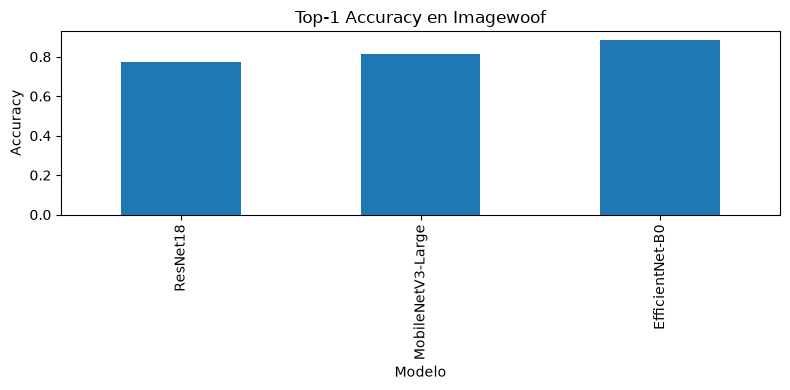

In [ ]:
results["accuracy"].plot(kind="bar", figsize=(8, 4))

plt.title("Top-1 Accuracy en Imagewoof")
plt.ylabel("Accuracy")
plt.xlabel("Modelo")
plt.tight_layout()
plt.show()

### Comparación de latencia

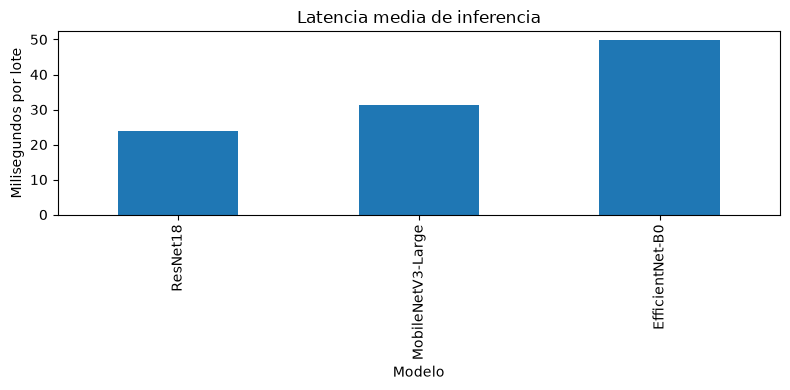

In [ ]:
results["mean_batch_ms"].plot(kind="bar", figsize=(8, 4))

plt.title("Latencia media de inferencia")
plt.ylabel("Milisegundos por lote")
plt.xlabel("Modelo")
plt.tight_layout()
plt.show()

### Comparación de throughput

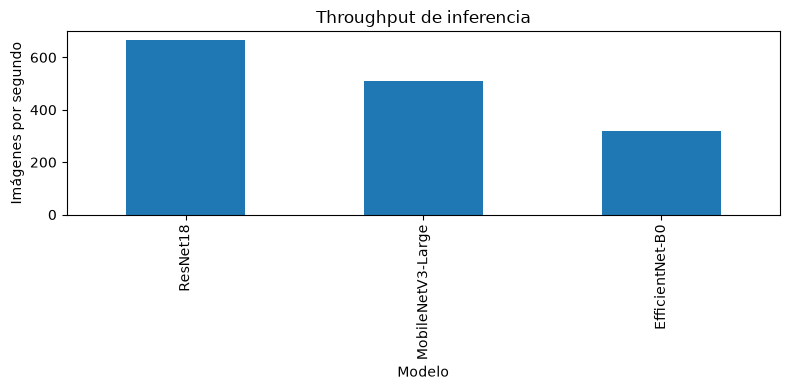

In [ ]:
results["images_per_second"].plot(kind="bar", figsize=(8, 4))

plt.title("Throughput de inferencia")
plt.ylabel("Imágenes por segundo")
plt.xlabel("Modelo")
plt.tight_layout()
plt.show()

### Relación entre accuracy y rendimiento

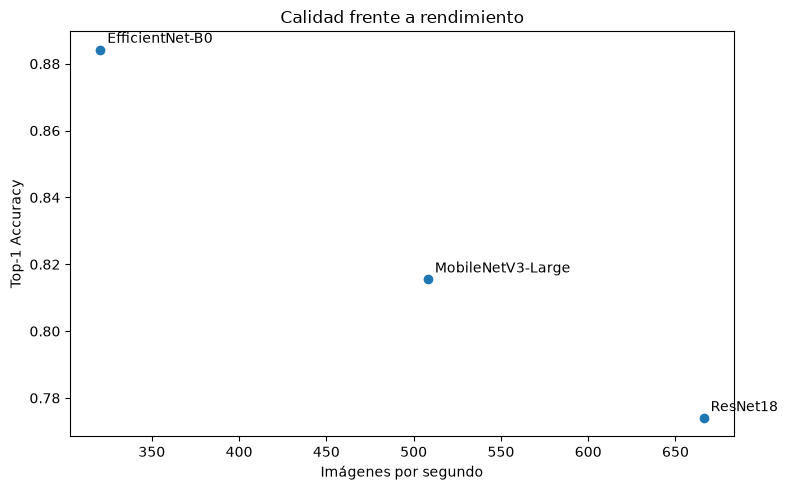

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(results["images_per_second"], results["accuracy"])

for name, row in results.iterrows():
    ax.annotate(
        name,(row["images_per_second"], row["accuracy"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

ax.set_xlabel("Imágenes por segundo")
ax.set_ylabel("Top-1 Accuracy")
ax.set_title("Calidad frente a rendimiento")

plt.tight_layout()
plt.show()